## Arquitectura básica de un CNN

Importante: En Entorno de Ejecución, Cambiar Tipo de Entorno de Ejecución, deben seleccionar GPU T4 para que ejecute rápido.

In [1]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt
import numpy as np

1. Dataset: CIFAR-10:
   * 60000 imágenes a color de 32 x 32
   * Maneja 10 clases de imágenes
   * 50000 imágenes de entrenamiento
   * 10000 imágenes de prueba

2. Carga y Normalización de los datos

Explicación de la siguiente expresión:

* `x_train = x_train.astype('float32') / 255.0`

Se usa para normalizar los valores de píxeles de las imágenes en una Red Neuronal Convolucional (CNN). Vamos a explicarlo paso a paso:

* `x_train`: Es el conjunto de imágenes de entrenamiento, normalmente con valores de píxeles en el rango de  0 (negro) a 255 (blanco), porque las imágenes se suelen representar en 8 bits por canal.
* `astype('float32')`:Convierte los valores enteros de los píxeles (tipo uint8) a números decimales de 32 bits (float32), necesarios para que la red neuronal procese los datos con mayor precisión.
* `/ 255.`0: Divide cada valor de píxel por 255, transformando el rango de valores de [0, 255] a [0.0, 1.0].


Cargando dataset CIFAR-10...
170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1277s 7us/step
Imágenes de entrenamiento: (50000, 32, 32, 3)
Imágenes de prueba: (10000, 32, 32, 3)


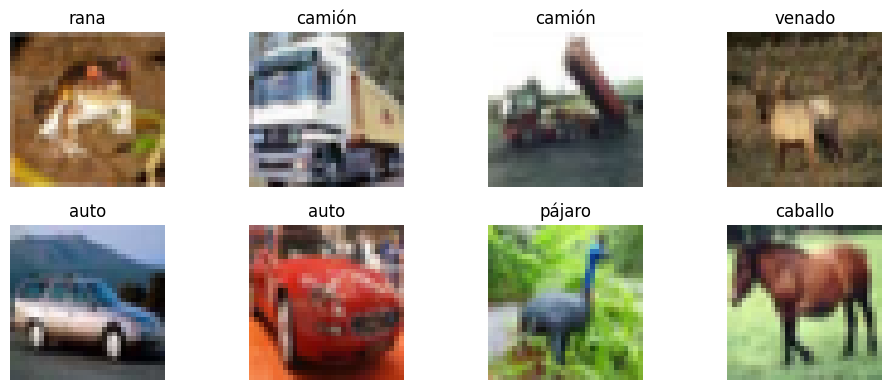

In [2]:
# Cargar dataset CIFAR-10 (imágenes reales)
print("Cargando dataset CIFAR-10...")
(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()

# Nombres de las clases
nombres_clases = ['avión', 'auto', 'pájaro', 'gato', 'venado',
                  'perro', 'rana', 'caballo', 'barco', 'camión']

print(f"Imágenes de entrenamiento: {x_train.shape}")
print(f"Imágenes de prueba: {x_test.shape}")

# Normalizar los valores de píxeles (0-255 -> 0-1)
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

# Mostrar algunas imágenes de ejemplo
plt.figure(figsize=(10, 4))
for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(x_train[i])
    plt.title(f'{nombres_clases[y_train[i][0]]}')
    plt.axis('off')
plt.tight_layout()
plt.show()

En el contexto de la configuración de las capas de los CNN se tiene la siguiente explicación:

* Caso de ejemplo: `layers.Conv2D(64, (3, 3), activation='relu', padding='same')`
* `64`: Significado: Número de filtros (también llamados kernels). Función: Cada filtro aprende a detectar una característica distinta (bordes, texturas, patrones) en la imagen de entrada. Resultado: La salida de esta capa tendrá 64 mapas de activación (uno por filtro).
* `(3, 3)`: Significado: Tamaño de cada filtro o kernel (alto × ancho). Función: Especifica que cada filtro es de 3x3 píxeles (3×3 espacial, y abarca todos los canales de entrada (3×3×3 en la primera capa)). Resultado: Cada filtro examina un área local de 3x3 de la imagen de entrada.
* `activation='relu'`: Significado: Función de activación aplicada al resultado de la convolución.Función: ReLU (Rectified Linear Unit). Resultado: Introduce no linealidad, permitiendo que la red aprenda representaciones más complejas.
* `padding='same'`: Significado: Define cómo manejar los bordes de la imagen al aplicar los filtros. Función: `same` añade relleno (padding) con ceros alrededor de la imagen de entrada para que la salida tenga el mismo tamaño espacial (alto y ancho) que la entrada. Resultado: Se preservan las dimensiones espaciales, útil cuando se desea mantener el tamaño constante en varias capas.

In [3]:
# Crear la red convolucional
def crear_cnn():
    model = keras.Sequential([
        # Entrada: imágenes 32x32 con 3 canales (RGB)
        layers.Input(shape=(32, 32, 3)),

        # Primera capa convolucional
        layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D((2, 2)),

        # Segunda capa convolucional
        layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D((2, 2)),

        # Tercera capa convolucional
        layers.Conv2D(64, (3, 3), activation='relu', padding='same'),

        # Aplanar para capas densas
        layers.Flatten(),      # Convierte (aplana) una entrada multidimensional —como un tensor 3D que proviene de una capa convolucional— en un vector 1D.
        layers.Dropout(0.5),  # Prevenir overfitting

        # Capas densas finales
        layers.Dense(64, activation='relu'),
        layers.Dense(10, activation='softmax')  # 10 clases de CIFAR-10
    ])

    return model

# Crear y compilar el modelo
modelo = crear_cnn()
modelo.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Mostrar arquitectura
print("\nArquitectura de la CNN:")
modelo.summary()



Arquitectura de la CNN:


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       262,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 319,178 (1.22 MB)

 Trainable params: 319,178 (1.22 MB)

 Non-trainable params: 0 (0.00 B)

In [4]:
# Entrenar el modelo
print("\nEntrenando el modelo...")
historia = modelo.fit(
    x_train, y_train,
    batch_size=32,
    epochs=10,
    validation_data=(x_test, y_test),
    verbose=1
)

# Evaluar el modelo
print("\nEvaluando el modelo...")
test_loss, test_accuracy = modelo.evaluate(x_test, y_test, verbose=0)
print(f"Precisión en test: {test_accuracy:.4f}")



Entrenando el modelo...
Epoch 1/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 36s 16ms/step - accuracy: 0.4460 - loss: 1.5212 - val_accuracy: 0.5553 - val_loss: 1.2068
Epoch 2/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.5910 - loss: 1.1441 - val_accuracy: 0.6455 - val_loss: 0.9958
Epoch 3/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.6495 - loss: 0.9945 - val_accuracy: 0.6469 - val_loss: 0.9955
Epoch 4/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.6818 - loss: 0.9013 - val_accuracy: 0.7034 - val_loss: 0.8547
Epoch 5/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.7055 - loss: 0.8333 - val_accuracy: 0.7126 - val_loss: 0.8260
Epoch 6/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.7249 - loss: 0.7788 - val_accuracy: 0.7026 - val_loss: 0.8339
Epoch 7/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.7362 - loss: 0.7405 - val_accuracy: 0.7338 - val_loss: 0.7769
Epoch 8/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accurac


Haciendo predicciones...
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step


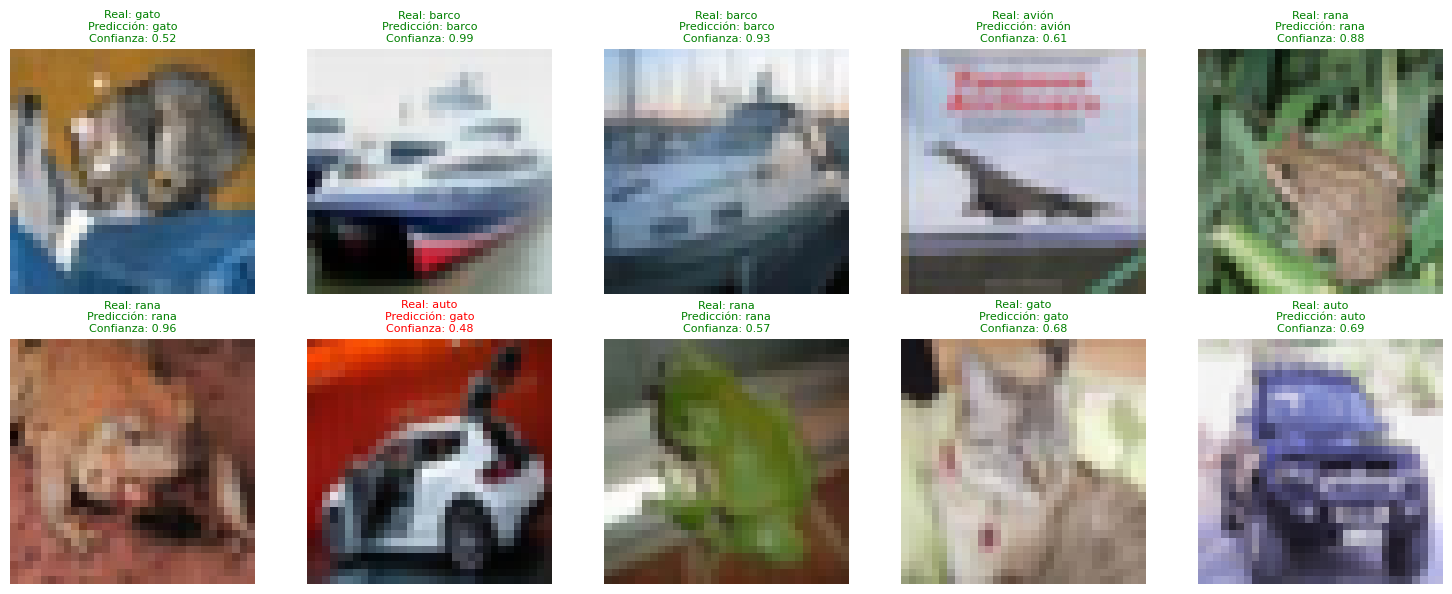

In [5]:
# Hacer predicciones en algunas imágenes
print("\nHaciendo predicciones...")
predicciones = modelo.predict(x_test[:10])

# Mostrar resultados
plt.figure(figsize=(15, 6))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[i])

    # Clase real vs predicha
    clase_real = nombres_clases[y_test[i][0]]
    clase_predicha = nombres_clases[np.argmax(predicciones[i])]
    confianza = np.max(predicciones[i])

    color = 'green' if clase_real == clase_predicha else 'red'
    plt.title(f'Real: {clase_real}\nPredicción: {clase_predicha}\nConfianza: {confianza:.2f}',
              color=color, fontsize=8)
    plt.axis('off')

plt.tight_layout()
plt.show()



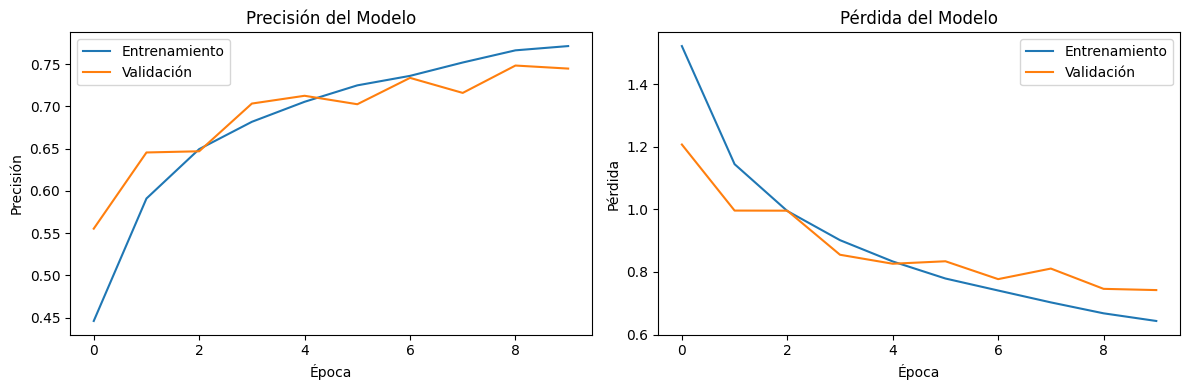


Modelo entrenado exitosamente!
Precisión final: 0.7448


In [6]:
# Mostrar gráfico de precisión durante entrenamiento
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(historia.history['accuracy'], label='Entrenamiento')
plt.plot(historia.history['val_accuracy'], label='Validación')
plt.title('Precisión del Modelo')
plt.xlabel('Época')
plt.ylabel('Precisión')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(historia.history['loss'], label='Entrenamiento')
plt.plot(historia.history['val_loss'], label='Validación')
plt.title('Pérdida del Modelo')
plt.xlabel('Época')
plt.ylabel('Pérdida')
plt.legend()

plt.tight_layout()
plt.show()

print(f"\nModelo entrenado exitosamente!")
print(f"Precisión final: {test_accuracy:.4f}")